# 第15章 模板匹配（跟随代码）

> 《OpenCV轻松入门：面向Python》第 15 章的跟随代码，内容未做改动。
> 运行前请确认工作目录为本文件夹（picture*.jpg 等素材都在这里）。

# 十五章 模板匹配

 在图像a中找到与图像b最相似的部分

 $$
 result=cv2.matchTemplate(image,templ,method,mask)
 $$
 - image: 待匹配图像
 - templ: 模板图像
 - method: 匹配方法，有六种：
     - cv2.TM_CCOEFF_NORMED: 基于相关性的匹配方法，计算两幅图像之间的相关性，并返回归一化的相关性值。
     - cv2.TM_CCOEFF: 基于相关性的匹配方法，计算两幅图像之间的相关性，并返回相关性值。
     - cv2.TM_CCORR_NORMED: 基于相关性的匹配方法，计算两幅图像之间的相关性，并返回归一化的相关性值。
   - cv2.TM_CCORR: 基于相关性的匹配方法，计算两幅图像之间的相关性，并返回相关性值。
   - cv2.TM_SQDIFF_NORMED: 基于平方差的匹配方法，计算两幅图像之间的平方差，并返回归一化的平方差值。
   - cv2.TM_SQDIFF: 基于平方差的匹配方法，计算两幅图像之间的平方差，并返回平方差值。
 - mask: 掩模图像，用于指定匹配区域，若为None则匹配整个图像
 - result: 匹配结果，是一个矩阵，矩阵的每个元素代表图像a中与模板图像最匹配的区域的位置

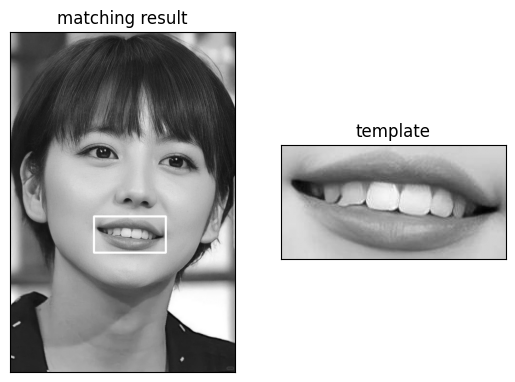

(273, 603)


In [265]:
img=cv2.imread("picture3.jpg",0)
templ=cv2.imread("picture3_mouth.jpg",0)

th,tw=templ.shape[::]
result=cv2.matchTemplate(img,templ,cv2.TM_CCOEFF)

minval,maxval,minloc,maxloc=cv2.minMaxLoc(result)

topleft=maxloc
bottomright=(topleft[0]+tw,topleft[1]+th)

cv2.rectangle(img,topleft,bottomright,255,5)

plt.subplot(121),plt.imshow(img,cmap='gray')
plt.title("matching result"),plt.xticks([]),plt.yticks([])
plt.subplot(122),plt.imshow(templ,cmap='gray')
plt.title("template"),plt.xticks([]),plt.yticks([])
plt.show()
print(topleft)


## 多模板匹配


In [266]:
a=np.array([3,4,9,7,2,6])
b=np.where(a>5)
print(b)


a=np.array([[1,2,10],[4,5,6],[7,8,9]])
b=np.where(a>5)
print(b)

(array([2, 3, 5]),)
(array([0, 1, 2, 2, 2]), array([2, 2, 0, 1, 2]))


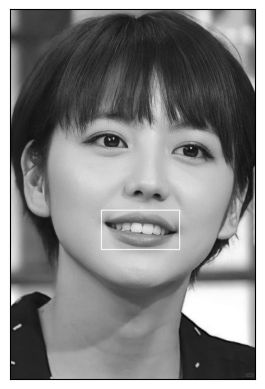

In [267]:
img=cv2.imread("picture3.jpg",0)
template=cv2.imread("picture3_mouth.jpg",0)

w,h=template.shape[::-1]

threshold=0.99

result=cv2.matchTemplate(img,template,cv2.TM_CCOEFF_NORMED)
loc=np.where(result>=threshold)

for pt in zip(*loc[::-1]):
    cv2.rectangle(img,pt,(pt[0]+w,pt[1]+h),255,2)
    plt.imshow(img,cmap='gray')
    plt.xticks([]),plt.yticks([])  # to hide tick values on X and Y axis
    plt.show()

